# Week 1 practical: the Bellman operator, and the contraction you can measure

**240MAR45 Reinforcement Learning in Robotics** | MSc Automatic Control and Robotics, UPC

Two jobs today. The first is administrative and takes ten minutes. We verify that the pinned
software stack works on your laptop. Relative to the second job, value iteration is claimed to
converge geometrically at rate $\gamma$. You will measure that rate and read it off a plot.

## Objectives

1. Confirm the pinned stack (`numpy`, `scipy`, `matplotlib`, `gymnasium`, `torch`) imports
   and runs.
2. Implement the Bellman optimality operator $\mathcal{T}$ as one line of array code, together
   with the greedy policy extraction that goes with it.
3. Measure $\|V_k - V^\star\|_\infty$ against the sweep index and recover $\ln\gamma$ as a slope.
4. Check the sweep-count formula $k \ge \ln(1/\eta)/\ln(1/\gamma)$ against what the algorithm
   actually needs.
5. See why the stopping test everybody writes, $\|V_k - V_{k-1}\|_\infty < \varepsilon$, does not
   measure the quantity you care about.

## Session plan

Everything here is done in the session, and there is no homework and no quizz.

| Part | Minutes |
|------|---------|
| 1. Smoke test, the whole pinned stack | 10 |
| 2 and 3. Recap and the pre-written gridworld | 10 |
| 4. The two blanked cores | 15 |
| 5 and 6. Runs, the contraction, the stopping-test trap | 20 |
| Checkpoints 1 to 6, written as you go | 20 |
| 7. Analysis and discussion | 10 |

Nothing here trains a neural network. The heaviest computation is 4000 sweeps over 25 states, and
no cell takes more than a few seconds. If you finish early, exercise 3.2 of the Week 1 notes takes
the same machinery to the Riccati recursion. That one is formative, so nobody collects it.

## 1. Smoke test (run this first)

If any line below fails, raise your hand before reading further. Do not start debugging your
Python installation on your own during the session.

In [ ]:
import sys
import platform
import time

t0 = time.time()

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from scipy.linalg import solve_continuous_are

print(f"python              {sys.version.split()[0]}  ({platform.system()})")
print(f"numpy               {np.__version__}")
print(f"scipy               {scipy.__version__}")
print(f"matplotlib          {matplotlib.__version__}")
print(f"gymnasium           {gym.__version__}")
print(f"torch               {torch.__version__}  (cuda available: {torch.cuda.is_available()})")

# One random rollout on the environment that returns in Week 2 as the falsifier.
env = gym.make("Pendulum-v1")
obs, info = env.reset(seed=0)
total = 0.0
for _ in range(200):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    total += reward
    if terminated or truncated:
        obs, info = env.reset()
env.close()
print(f"\nrandom-policy return over 200 steps: {total:.1f}")

# The classical-control half of the course carries as much weight as the learning half all term.
# There is no control library in the stack, so scipy solves the Riccati equation and the gain is
# written out, which is the formula the notes derive.
A_c = np.array([[0.0, 1.0], [0.0, 0.0]])
B_c = np.array([[0.0], [1.0]])
P_c = solve_continuous_are(A_c, B_c, np.eye(2), np.eye(1))
K_c = np.linalg.solve(np.eye(1), B_c.T @ P_c)          # R^{-1} B' P
print(f"continuous-time LQR gain on a double integrator: K = {K_c.ravel()}  (exact: [1, sqrt(3)])")

print(f"\nsetup OK  ({time.time() - t0:.1f} s)")

python              3.13.15  (Linux)
numpy               2.1.3
scipy               1.16.3
matplotlib          3.10.0
gymnasium           1.3.0
torch               2.11.0+cpu  (cuda available: False)

random-policy return over 200 steps: -906.4
continuous-time LQR gain on a double integrator: K = [1.         1.73205081]  (exact: [1, sqrt(3)])

setup OK  (7.7 s)


The GPU line is informational. Everything in this course runs on a CPU, the cumulative project
included. `mujoco` and `pybullet` belong to the pinned stack as well and are first needed in
Week 9, so the next cell reports on them without failing if they are absent. Install them before
Week 9. PPO and SAC arrive in Week 10 as two single-file implementations inside the project
codebase, so there is no reinforcement-learning library to install at any point.

In [ ]:
for pkg in ("mujoco", "pybullet"):
    try:
        mod = __import__(pkg)
        print(f"{pkg:10s} {getattr(mod, '__version__', 'installed')}")
    except ImportError:
        print(f"{pkg:10s} MISSING (not needed until Week 9, install before then)")

mujoco     MISSING (not needed until Week 9, install before then)
pybullet   MISSING (not needed until Week 9, install before then)


## 2. Recap

The Bellman optimality equation characterises $V^\star$ implicitly, as the fixed point of an
operator acting on functions,

$$ (\mathcal{T}V)(x) \;=\; \max_{u}\; \mathbb{E}_w\!\left[\, r(x,u,w)
   + \gamma\, V\big(f(x,u,w)\big) \right]. $$

In the tabular case a value function is a vector of length $|\mathcal{X}|$, and $\mathcal{T}$ is
a few array operations. Value iteration applies it repeatedly from an arbitrary $V_0$. The
theorem asserted in Week 1 and proved in Week 3 says $\mathcal{T}$ is a $\gamma$-contraction in
the supremum norm, so $\|V_k - V^\star\|_\infty \le \gamma^k \|V_0 - V^\star\|_\infty$ and the
iterates are funnelled onto the unique fixed point from anywhere.

Background reading: lecture notes section 3.5 (value iteration) and 3.6 (contraction,
numerically), plus the concept notes `Bellman operator`, `Value iteration`, `Discount factor`
and `Value function`.

## 3. Pre-written infrastructure

The world is the $5 \times 5$ stochastic gridworld of the Week 1 figure. Four actions. With
probability $0.9$ the intended move happens, and with probability $0.05$ each the agent slips to
a perpendicular direction. Three cells are blocked, the goal cell is absorbing and pays $+1$ per
step, and any move into a wall, off the grid, or into a blocked cell leaves the state unchanged.

The absorbing rewarding goal keeps the problem genuinely infinite-horizon. A terminating goal
would hide the geometric rate behind a finite-time effect.

Cells are named `(row, col)` with 1-based indices and row 1 at the top, matching the notes.

In [ ]:
NROW, NCOL = 5, 5
NS, NA = NROW * NCOL, 4
OBSTACLES = [(2, 2), (3, 4), (4, 2)]   # blocked cells
GOAL = (5, 5)                          # absorbing, pays +1 per step
P_SLIP = 0.10                          # total slip probability, split over the two perpendiculars

# action index -> (drow, dcol).  0 = N, 1 = S, 2 = E, 3 = W  (N decreases the row)
MOVES = {0: (-1, 0), 1: (1, 0), 2: (0, 1), 3: (0, -1)}
PERP = {0: (2, 3), 1: (2, 3), 2: (0, 1), 3: (0, 1)}
ARROW = {0: "^", 1: "v", 2: ">", 3: "<"}


def cell_to_state(r, c):
    """1-based (row, col) to flat state index."""
    return (r - 1) * NCOL + (c - 1)


def build_gridworld(p_slip=P_SLIP):
    """Return P of shape (nS, nA, nS) and R of shape (nS, nA).

    R holds the expected immediate reward, which here is deterministic given (s, a).
    """
    obstacles = {cell_to_state(r, c) for r, c in OBSTACLES}
    goal = cell_to_state(*GOAL)
    P = np.zeros((NS, NA, NS))
    R = np.zeros((NS, NA))

    for r in range(1, NROW + 1):
        for c in range(1, NCOL + 1):
            s = cell_to_state(r, c)
            if s in obstacles:
                P[s, :, s] = 1.0          # never entered. The self-loop keeps P stochastic
                continue
            if s == goal:
                P[s, :, s] = 1.0          # absorbing
                R[s, :] = 1.0             # +1 per step, forever
                continue
            for a in range(NA):
                outcomes = ((a, 1.0 - p_slip),
                            (PERP[a][0], p_slip / 2),
                            (PERP[a][1], p_slip / 2))
                for b, prob in outcomes:
                    dr, dc = MOVES[b]
                    r1, c1 = r + dr, c + dc
                    if not (1 <= r1 <= NROW and 1 <= c1 <= NCOL):
                        s_next = s        # bounced off the boundary
                    else:
                        s_next = cell_to_state(r1, c1)
                        if s_next in obstacles:
                            s_next = s    # bounced off an obstacle
                    P[s, a, s_next] += prob
    return P, R


P, R = build_gridworld()
assert np.allclose(P.sum(axis=2), 1.0), "each row of P must be a probability distribution"
print(f"gridworld built: P {P.shape}, R {R.shape}")


gridworld built: P (25, 4, 25), R (25, 4)


### Hyperparameters

These are the values that produced the figure in the notes. Change them later, once the
reproduction works.

In [ ]:
GAMMAS = (0.90, 0.95, 0.99)   # the three discount factors of the Week 1 figure
SEED = 0                      # V_0 is random on purpose, so fix the seed to keep plots comparable
V0_RANGE = 10.0               # V_0 ~ Uniform(-10, 10) at every state, deliberately not zero
TOL_STAR = 1e-14              # accuracy of the reference V*, essentially machine precision
ERROR_FLOOR = 1e-12           # stop tracking a run once it reaches numerical noise
MAX_SWEEPS = 4000             # generous cap. gamma = 0.99 needs roughly 2700 sweeps

rng = np.random.default_rng(SEED)
V0 = V0_RANGE * (2.0 * rng.random(NS) - 1.0)
print(f"V0 in [{V0.min():.2f}, {V0.max():.2f}]")

V0 in [-9.95, 8.70]


### Plotting helpers (nothing to fill in here)

In [ ]:
COLORS = ["#0072B2", "#D55E00", "#009E73"]


def plot_error_curves(curves, bounds, gammas, ax=None):
    """Log-scale plot of ||V_k - V*||_inf against the sweep index, with the theoretical bound."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6.2, 4.0))
    for i, g in enumerate(gammas):
        k = np.arange(len(curves[i]))
        # The bound is drawn thick and grey underneath, because on this problem the measured
        # error lands on top of it. A thin dashed line would simply disappear.
        ax.semilogy(k, bounds[i], "--", color="0.72", lw=4.0, dashes=(4, 2))
        ax.semilogy(k, curves[i], "-", color=COLORS[i % 3], lw=1.5,
                    label=rf"$\gamma = {g:.2f}$")
    ax.set_xlabel("value-iteration sweep $k$")
    ax.set_ylabel(r"$\|V_k - V^\star\|_\infty$")
    ax.grid(alpha=0.15)
    ax.legend(frameon=False)
    ax.text(0.46, 0.10, "grey: the bound " + r"$\gamma^k \|V_0 - V^\star\|_\infty$",
            transform=ax.transAxes, color="0.45", fontsize=9)
    return ax


def plot_value_and_policy(V, pi, title="", ax=None):
    """Heatmap of V with the greedy action drawn in every cell."""
    if ax is None:
        _, ax = plt.subplots(figsize=(4.8, 4.2))
    obstacles = {cell_to_state(r, c) for r, c in OBSTACLES}
    goal = cell_to_state(*GOAL)
    grid = V.reshape(NROW, NCOL)
    mask = [[cell_to_state(r, c) in obstacles for c in range(1, NCOL + 1)]
            for r in range(1, NROW + 1)]
    im = ax.imshow(np.ma.masked_array(grid, mask=mask), cmap="viridis", origin="upper")
    for r in range(1, NROW + 1):
        for c in range(1, NCOL + 1):
            s = cell_to_state(r, c)
            if s in obstacles:
                label = "#"
            elif s == goal:
                label = "G"
            else:
                label = ARROW[int(pi[s])]
            ax.text(c - 1, r - 1, label, ha="center", va="center",
                    color="w", fontsize=13, fontweight="bold")
    ax.set_xticks(range(NCOL))
    ax.set_xticklabels([str(c) for c in range(1, NCOL + 1)])
    ax.set_yticks(range(NROW))
    ax.set_yticklabels([str(r) for r in range(1, NROW + 1)])
    ax.set_xlabel("column")
    ax.set_ylabel("row")
    ax.set_title(title)
    plt.colorbar(im, ax=ax, shrink=0.8)
    return ax

## 4. The conceptual core

The state-action value

$$ Q(x,u) \;=\; r(x,u) + \gamma \sum_{x'} p(x' \mid x, u)\, V(x') $$

closed by a $\max$ is the operator $\mathcal{T}$, and closed by an $\arg\max$ it is the greedy
policy. With `P` of shape `(nS, nA, nS)` and `V` of shape `(nS,)`, the sum over successors is
`np.einsum('san,n->sa', P, V)`.

In [ ]:
def bellman_backup(V, P, R, gamma):
    """One synchronous sweep of the Bellman optimality operator.

    P : (nS, nA, nS) transition probabilities
    R : (nS, nA)     expected immediate reward
    V : (nS,)        current value function
    Returns (T V) evaluated at every state, shape (nS,).
    """
    # Self-written: So the idea is to run a for loop to
    Q = R + gamma * np.einsum('san,n->sa',P, V);
    return np.max(Q, axis=1)
    # ===== YOUR CODE HERE (2 lines) =============================
    # Goal: return max_u [ R(x,u) + gamma * sum_{x'} P(x'|x,u) V(x') ] at every state x.
    # Hint: the Bellman optimality operator of notes section 3.4. Build Q of shape (nS, nA)
    #       with the einsum above, then reduce over the action axis.
    # ============================================================


def greedy_policy(V, P, R, gamma):
    """The greedy policy with respect to V, as an integer action index per state, shape (nS,)."""
    # 1. Compute identical Q-values: shape (nS, nA)
    Q = R + gamma * np.einsum('san,n->sa', P, V)
    # ===== YOUR CODE HERE (2 lines) =============================
    # Goal: return argmax_u [ R(x,u) + gamma * sum_{x'} P(x'|x,u) V(x') ] at every state x.
    # Hint: the same Q as above, closed by argmax instead of max. Line 6 of the value-iteration
    #       algorithm in notes section 3.5.
    # ============================================================
    return np.argmax(Q, axis=1)

Everything from here on is pre-written and calls the two functions above.

In [ ]:
def value_iteration(P, R, gamma, V0, n_sweeps):
    """Run n_sweeps of value iteration from V0. Returns the history, shape (n_sweeps+1, nS)."""
    V, history = V0.copy(), [V0.copy()]
    for _ in range(n_sweeps):
        V = bellman_backup(V, P, R, gamma)
        history.append(V.copy())
    return np.array(history)


def reference_solution(P, R, gamma, tol=TOL_STAR, max_it=200_000):
    """V* to machine precision, obtained by iterating T from zero until it stops moving."""
    V = np.zeros(P.shape[0])
    for _ in range(max_it):
        V_new = bellman_backup(V, P, R, gamma)
        if np.max(np.abs(V_new - V)) < tol:
            return V_new
        V = V_new
    raise RuntimeError("reference solution did not converge")


# A sanity check on the operator before any plot is allowed to depend on it. At gamma = 0 one
# backup must return exactly max_u R(x,u), whatever V it was handed.
_test = bellman_backup(np.full(NS, 123.4), P, R, 0.0)
assert np.allclose(_test, R.max(axis=1)), "at gamma = 0 the backup must ignore V entirely"
print("operator sanity check passed")

operator sanity check passed


### Checkpoint 1

The sanity check above sets $\gamma = 0$ and demands $\max_u R(x,u)$ back, whatever $V$ it was
handed. Name the two operations of the backup that this call does verify, and the one it leaves
completely untested.

## 5. Run: measure the contraction rate

For each $\gamma$ we compute a reference $V^\star$, run value iteration from the random $V_0$,
and record $\|V_k - V^\star\|_\infty$ at every sweep.

gamma = 0.90: 258 sweeps tracked, V* range [0.00, 10.00]
gamma = 0.95: 532 sweeps tracked, V* range [0.00, 20.00]
gamma = 0.99: 2742 sweeps tracked, V* range [0.00, 100.00]


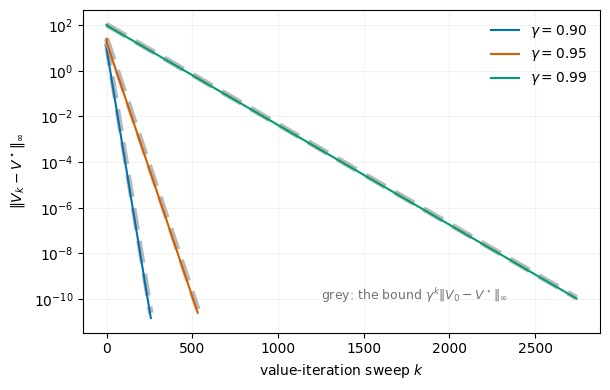

In [ ]:
curves, bounds, histories, V_stars = [], [], [], []

for gamma in GAMMAS:
    V_star = reference_solution(P, R, gamma)
    hist = value_iteration(P, R, gamma, V0, MAX_SWEEPS)
    err = np.max(np.abs(hist - V_star), axis=1)

    # Truncate once the error reaches numerical noise, where the log plot stops meaning anything.
    below = np.flatnonzero(err < ERROR_FLOOR * err[0])
    if below.size:
        err = err[:below[0] + 1]

    curves.append(err)
    bounds.append(err[0] * gamma ** np.arange(len(err)))
    histories.append(hist)
    V_stars.append(V_star)
    print(f"gamma = {gamma:.2f}: {len(err) - 1} sweeps tracked, "
          f"V* range [{V_star.min():.2f}, {V_star.max():.2f}]")

plot_error_curves(curves, bounds, GAMMAS)
plt.tight_layout()
plt.show()

Straight lines on a log scale are the signature of geometric decay, and each coloured curve sits
on its grey bound rather than dropping away from it. Fit the asymptotic slope and compare it with
$\ln\gamma$. The plotted axis is base 10, so a slope measured with a ruler on the


figure is $\log_{10}\gamma$, while the numbers printed below are natural logarithms.

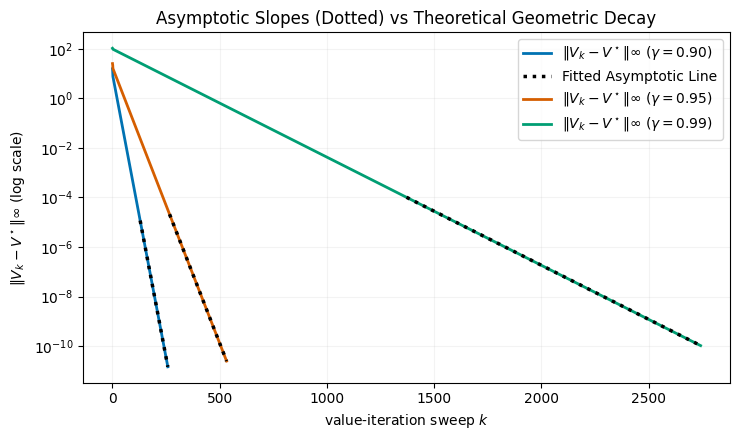

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.5, 4.5))

for i, gamma in enumerate(GAMMAS):
    e = curves[i]
    k = np.arange(len(e))

    # Plot the original error curves
    ax.semilogy(k, e, "-", color=COLORS[i % 3], lw=2.0, label=rf"$\|V_k - V^\star\|\infty$ ($\gamma = {gamma:.2f}$)")

    # Define the asymptotic segment (second half of the run)
    i1, i2 = len(e) // 2, len(e) - 1

    # Compute the theoretical progression using the slope ln(gamma) starting from the error at i1
    fitted_asymptotic = e[i1] * np.exp(np.log(gamma) * (k[i1:] - i1))

    # Plot the fitted slope segment
    ax.semilogy(k[i1:], fitted_asymptotic, ":", color="black", lw=2.5,
                label="Fitted Asymptotic Line" if i == 0 else "")

ax.set_xlabel("value-iteration sweep $k$")
ax.set_ylabel(r"$\|V_k - V^\star\|\infty$ (log scale)")
ax.set_title("Asymptotic Slopes (Dotted) vs Theoretical Geometric Decay")
ax.grid(True, which="both", alpha=0.15)
ax.legend(frameon=True, loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
print(f"{'gamma':>7} {'measured slope':>16} {'ln(gamma)':>12} {'relative error':>16}")
for i, gamma in enumerate(GAMMAS):
    e = curves[i]
    i1, i2 = len(e) // 2, len(e) - 1          # asymptotic segment, the second half of the run
    slope = (np.log(e[i2]) - np.log(e[i1])) / (i2 - i1)
    print(f"{gamma:7.2f} {slope:16.6f} {np.log(gamma):12.6f} "
          f"{abs(slope - np.log(gamma)) / abs(np.log(gamma)):16.2e}")

  gamma   measured slope    ln(gamma)   relative error
   0.90        -0.105361    -0.105361         0.00e+00
   0.95        -0.051304    -0.051293         2.14e-04
   0.99        -0.010055    -0.010050         4.24e-04


### Checkpoint 2

The fitted slope at $\gamma = 0.99$ is $-0.0101$ per sweep. What quantity is that number, and
would it change if you replaced the random $V_0$ by the zero vector?

Answer: Everytime there is a sweep, the error decays with 0.99. 0.99^n is an exponential decay. To turn this into a straight line, we take the natural log of the exponential

$$e_k = e_0 \cdot \gamma^k$$

The way to look at it is also that you are losing 1% of your error per decay and retaining 99% of it!

Slope ($\ln \gamma$): "How fast does error shrink per step?" (Property of the algorithm/environment).Intercept ($V_0$): "How far away am I when I press start?" (Property of your initialization).

### The sweep-count formula

Reducing the initial error by a factor $\eta$ needs $k \ge \ln(1/\eta)/\ln(1/\gamma)$ sweeps. At
$\eta = 10^{-2}$ the notes quote 44, 90 and 459. Check them against the run.

In [ ]:
eta = 1e-2
print(f"{'gamma':>7} {'predicted k':>13} {'measured k':>12}")
for i, gamma in enumerate(GAMMAS):
    predicted = int(np.ceil(np.log(1 / eta) / np.log(1 / gamma)))
    measured = int(np.argmax(curves[i] <= eta * curves[i][0]))
    print(f"{gamma:7.2f} {predicted:13d} {measured:12d}")

  gamma   predicted k   measured k
   0.90            44           39
   0.95            90           83
   0.99           459          452


### Checkpoint 3

At $\gamma = 0.95$ the formula predicts 90 sweeps for a factor $10^{2}$, and the run needed 83.
Is the formula wrong? Say which of the two numbers is the worst case, and whether a run could
ever beat the prediction in the decay *rate* rather than in the count.



The measured count sits at or slightly below the prediction. The bound holds for the worst case
over initial conditions, and this particular $V_0$ is not the worst case.

## 6. Why the stopping test misleads you

Every implementation stops on $\|V_k - V_{k-1}\|_\infty < \varepsilon$, because $V^\star$ is
unavailable at run time. The error you care about is larger than that quantity by roughly a
factor $\gamma/(1 - \gamma)$, which is 99 at $\gamma = 0.99$. The next plot puts the two on the
same axes.

In [ ]:
i99 = GAMMAS.index(0.99)
hist99, Vstar99 = histories[i99], V_stars[i99]
n = len(curves[i99])
true_err = curves[i99]
succ_diff = np.max(np.abs(np.diff(hist99[:n], axis=0)), axis=1)

fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.semilogy(np.arange(n), true_err, color=COLORS[0], lw=1.8,
            label=r"$\|V_k - V^\star\|_\infty$  (what you want)")
ax.semilogy(np.arange(1, n), succ_diff, color=COLORS[1], lw=1.8,
            label=r"$\|V_k - V_{k-1}\|_\infty$  (what you can measure)")
ax.axhline(1e-3, color="0.4", ls=":", lw=1.0)
ax.text(0.02, 1.3e-3, r"$\varepsilon = 10^{-3}$", color="0.4", fontsize=9,
        transform=ax.get_yaxis_transform())
ax.set_xlabel("value-iteration sweep $k$")
ax.set_ylabel("supremum norm")
ax.set_title(r"$\gamma = 0.99$")
ax.grid(alpha=0.15)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

k_stop = int(np.argmax(succ_diff < 1e-3)) + 1
print(f"stopping test fires at sweep      {k_stop}")
print(f"true error there                  {true_err[k_stop]:.3e}")
print(f"ratio to the tolerance            {true_err[k_stop] / 1e-3:.1f}x")
print(f"gamma / (1 - gamma)               {0.99 / 0.01:.1f}")

### Checkpoint 4

The run stopped when successive sweeps differed by less than $\varepsilon = 10^{-3}$. How far
from $V^\star$ was it at that moment? Give the number you measured, and the general factor that
converts the test you can run into the error you care about.

The two curves run parallel, separated by two orders of magnitude. A run stopped at
$\varepsilon = 10^{-3}$ is still around $10^{-1}$ away from $V^\star$. Week 3 turns this
observation into a certificate and bounds the suboptimality of the policy extracted at the stop.

That policy is the second half of the story. Values and policies do not converge together.

In [ ]:
pi_star = greedy_policy(Vstar99, P, R, 0.99)
pi_hist = np.array([greedy_policy(V, P, R, 0.99) for V in hist99[:n]])
disagreement = (pi_hist != pi_star).sum(axis=1)
wrong = np.flatnonzero(disagreement > 0)
settled = int(wrong[-1] + 1) if wrong.size else 0

fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.plot(np.arange(n), disagreement, color=COLORS[2], lw=1.8)
ax.axvline(settled, color="0.4", ls=":", lw=1.0)
ax.set_xlabel("value-iteration sweep $k$")
ax.set_ylabel("states where the greedy action\ndiffers from the optimal one")
ax.set_xlim(0, min(n, 4 * settled + 20))
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

print(f"greedy policy is optimal from sweep       {settled}")
print(f"value error at that sweep                 {true_err[settled]:.3e}")
print(f"sweeps needed for a 1e-6 value error      {int(np.argmax(true_err < 1e-6))}")

### Checkpoint 5

The greedy policy stopped changing at sweep 12, while the value error needed 1831 sweeps to reach
$10^{-6}$. Which of the two numbers matters for a controller you are about to deploy, and what
does your answer say about stopping value iteration early?

The policy is right long before the values are. That gap is the reason approximate methods work
at all, and Week 3 supplies the bound that makes it quantitative.

Finally, look at what was computed.

In [ ]:
plot_value_and_policy(Vstar99, pi_star,
                      title=r"$V^\star$ and the greedy policy, $\gamma = 0.99$")
plt.tight_layout()
plt.show()

### Checkpoint 6

`bellman_backup` used the model in exactly two places. Name them. Then place what you just ran on
the unifying diagram: which column, which row, and which Bellman object does it approximate?

## 7. Analysis

Answer these in the notebook, a few sentences each. They come back in the Week 3 session.

1. The measurement lands on the bound instead of dropping below it. What does that say about how
   much conservatism is left in the contraction estimate, and about how much a good guess for
   $V_0$ can buy you?

2. Re-run section 5 with `V0 = np.zeros(NS)`. The curves move. Do the slopes? Say which of the
   two quantities in $\|V_k - V^\star\|_\infty \le \gamma^k \|V_0 - V^\star\|_\infty$ your
   initialisation controls.

3. At $\gamma = 0.99$ the effective planning horizon is $1/(1-\gamma) = 100$ steps and the run
   needs about 460 sweeps for two digits. Each sweep costs
   $|\mathcal{X}|\,|\mathcal{U}|\,|\mathcal{X}|$. Write down both factors for a 7-DOF arm
   discretised at 100 bins per dimension. Which factor is the one that kills you, and is $\gamma$
   the knob that fixes it?